/tmp/ipykernel_30/2313225609.py:21: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, pooling='avg')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Found 3028 images belonging to 4 classes.
Found 280 images belonging to 4 classes.
Found 88 images belonging to 4 classes.


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1730972165.624753      92 service.cc:145] XLA service 0x7d0a48002450 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1730972165.624819      92 service.cc:153]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0


 2/95 ━━━━━━━━━━━━━━━━━━━━ 11s 120ms/step

I0000 00:00:1730972176.335467      92 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


95/95 ━━━━━━━━━━━━━━━━━━━━ 297s 3s/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 35s 4s/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       116
           1       0.74      0.70      0.72        44
           2       1.00      0.88      0.93        40
           3       0.84      0.86      0.85        80

    accuracy                           0.90       280
   macro avg       0.88      0.86      0.87       280
weighted avg       0.90      0.90      0.90       280



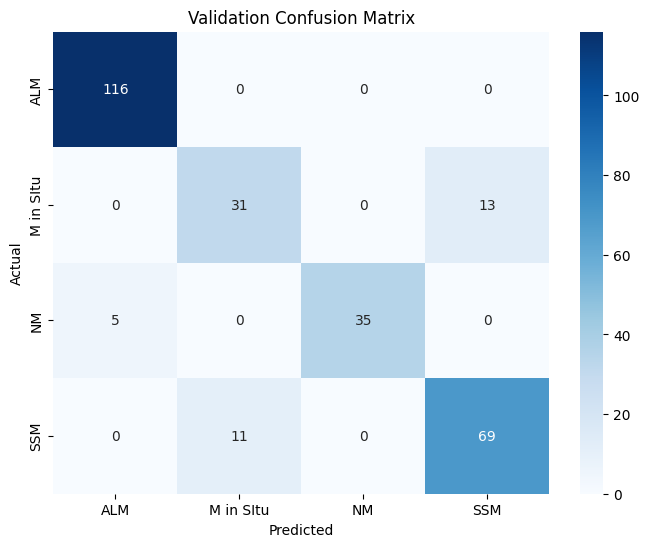

Test Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.96      0.93        26
           1       0.84      0.88      0.86        24
           2       0.94      0.83      0.88        18
           3       0.79      0.75      0.77        20

    accuracy                           0.86        88
   macro avg       0.86      0.85      0.86        88
weighted avg       0.86      0.86      0.86        88



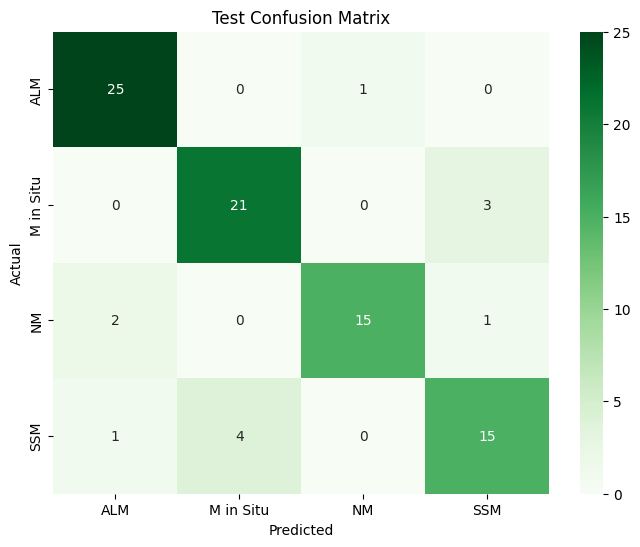

XGBoost model saved to xgboost_MobileNetV2_model.joblib
Predictions saved to test_predictions_xgb_mobilenetv2.csv


In [1]:
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pandas as pd


train_dir = '/kaggle/input/train-save'
val_dir = '/kaggle/input/valid-save'
test_dir = '/kaggle/input/test-save'


model_path = 'xgboost_MobileNetV2_model.joblib'


base_model = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, pooling='avg')

datagen = ImageDataGenerator(rescale=1./255)


train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary',  
    shuffle=False
)

val_generator = datagen.flow_from_directory(
    val_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

def extract_features(generator):
    features = base_model.predict(generator)
    labels = generator.classes
    return features, labels


train_features, train_labels = extract_features(train_generator)
val_features, val_labels = extract_features(val_generator)
test_features, test_labels = extract_features(test_generator)


xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
xgb_model.fit(train_features, train_labels)


val_predictions = xgb_model.predict(val_features)
print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions))

val_cm = confusion_matrix(val_labels, val_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(val_cm, annot=True, fmt="d", cmap="Blues", xticklabels=train_generator.class_indices.keys(), yticklabels=train_generator.class_indices.keys())
plt.title("Validation Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


test_predictions = xgb_model.predict(test_features)
print("Test Classification Report:")
print(classification_report(test_labels, test_predictions))


test_cm = confusion_matrix(test_labels, test_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Greens", xticklabels=test_generator.class_indices.keys(), yticklabels=test_generator.class_indices.keys())
plt.title("Test Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


joblib.dump(xgb_model, model_path)
print(f"XGBoost model saved to {model_path}")


pred_proba = xgb_model.predict_proba(test_features)
predictions_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'Prediction': test_predictions,
    'Confidence': [max(proba) for proba in pred_proba]
})
predictions_df.to_csv("test_predictions_xgb_mobilenetv2.csv", index=False)
print("Predictions saved to test_predictions_xgb_mobilenetv2.csv")


Model loaded from /kaggle/working/xgboost_MobileNetV2_model.joblib
Found 88 images belonging to 4 classes.


/tmp/ipykernel_30/3812181603.py:30: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, pooling='avg')
/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step 
Predictions, True Labels, and Confidence Scores:
                                    Image  True Label  Prediction  Confidence
0               ALM/d132642d-IMG_2864.JPG           0           0    0.999897
1               ALM/d1805016-IMG_1912.JPG           0           0    0.999400
2               ALM/d27694e9-IMG_2746.JPG           0           0    0.999542
3               ALM/d55466c0-IMG_2954.JPG           0           0    0.998657
4               ALM/d7060567-IMG_1911.JPG           0           0    0.999731
..                                    ...         ...         ...         ...
83  SSM/e2e461f8-ISIC_0023290_flipped.JPG           3           3    0.998789
84              SSM/e55f3358-IMG_2128.JPG           3           0    0.535672
85      SSM/e55f3358-IMG_2128_flipped.JPG           3           3    0.623766
86          SSM/e9a09f6b-ISIC_0023277.JPG           3           3    0.946640
87  SSM/e9a09f6b-ISIC_0023277_flipped.JPG           3  

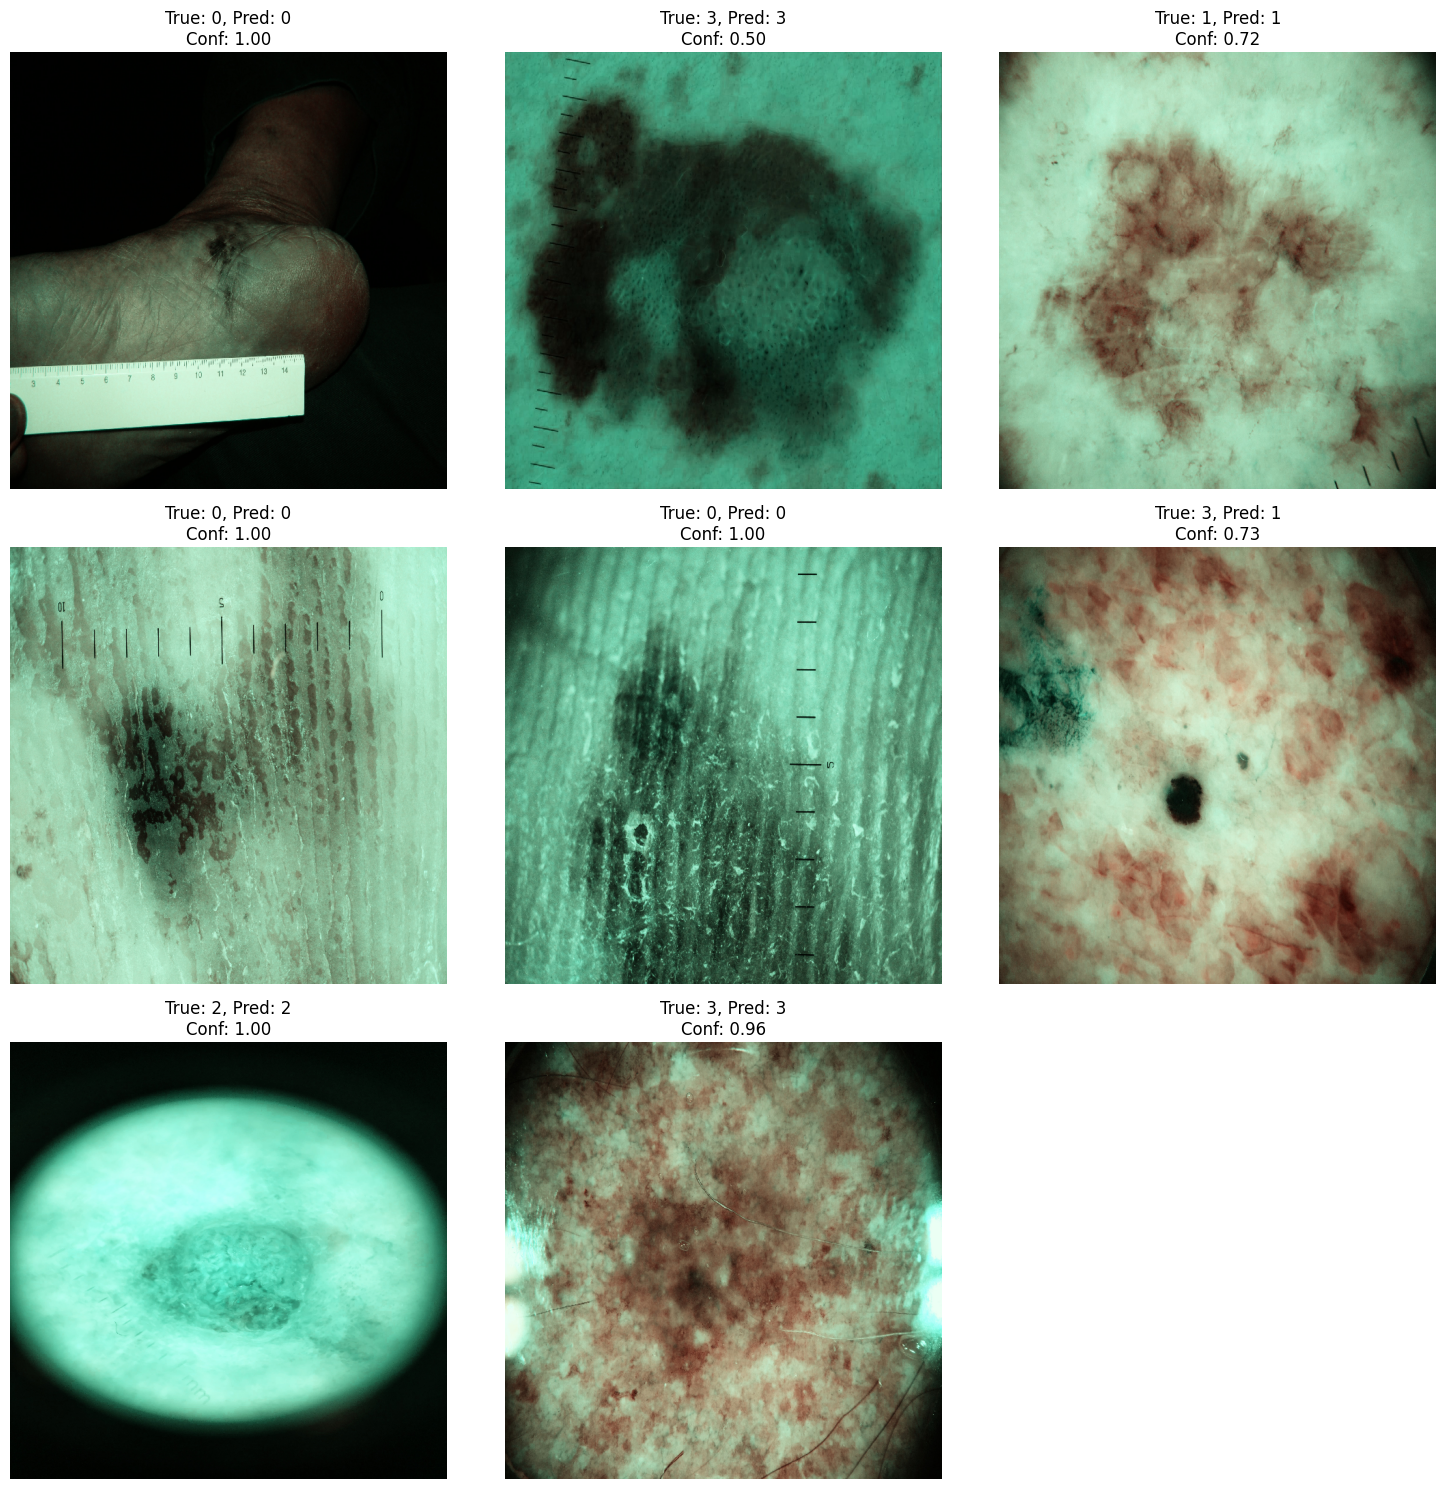

Predictions saved to test_predictions_xgb_mobilenetv2.csv


In [3]:
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import xgboost as xgb
import joblib
import pandas as pd
import matplotlib.pyplot as plt


test_dir = '/kaggle/input/test-save'
model_path = '/kaggle/working/xgboost_MobileNetV2_model.joblib'


xgb_model = joblib.load(model_path)
print(f"Model loaded from {model_path}")


datagen = ImageDataGenerator(rescale=1./255)
test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


base_model = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, pooling='avg')

def extract_features(generator):
    features = base_model.predict(generator)
    return features


test_features = extract_features(test_generator)


test_predictions = xgb_model.predict(test_features)
pred_proba = xgb_model.predict_proba(test_features)


predictions_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'True Label': test_generator.classes,  
    'Prediction': test_predictions,
    'Confidence': [max(proba) for proba in pred_proba]
})


print("Predictions, True Labels, and Confidence Scores:")
print(predictions_df[['Image', 'True Label', 'Prediction', 'Confidence']])


num_images = 8
indices = np.random.choice(len(predictions_df), num_images, replace=False)

plt.figure(figsize=(15, 15))
for i, idx in enumerate(indices):
    img_path = os.path.join(test_dir, predictions_df.loc[idx, 'Image'])
    img = image.load_img(img_path, target_size=(640, 640))
    img_array = image.img_to_array(img) / 255.0  
    
    true_label = predictions_df.loc[idx, 'True Label']
    predicted_label = predictions_df.loc[idx, 'Prediction']
    confidence = predictions_df.loc[idx, 'Confidence']

    plt.subplot(3, 3, i + 1)
    plt.imshow(img_array)
    plt.axis('off')
    plt.title(f"True: {true_label}, Pred: {predicted_label}\nConf: {confidence:.2f}")

plt.tight_layout()
plt.show()


predictions_df.to_csv("test_predictions_xgb_mobilenetv2.csv", index=False)
print("Predictions saved to test_predictions_xgb_mobilenetv2.csv")


/tmp/ipykernel_30/2157012318.py:21: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, pooling='avg')


Found 3028 images belonging to 4 classes.
Found 280 images belonging to 4 classes.
Found 88 images belonging to 4 classes.


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


95/95 ━━━━━━━━━━━━━━━━━━━━ 236s 2s/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       116
           1       0.77      0.77      0.77        44
           2       1.00      0.90      0.95        40
           3       0.86      0.88      0.87        80

    accuracy                           0.91       280
   macro avg       0.90      0.89      0.89       280
weighted avg       0.92      0.91      0.91       280



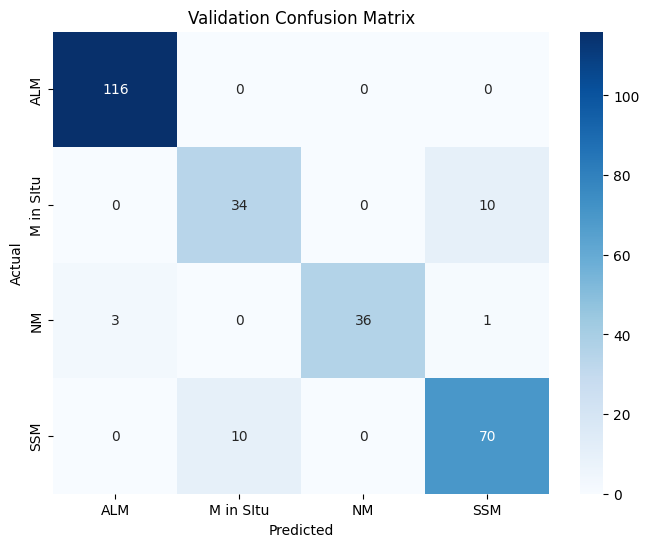

Test Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95        26
           1       1.00      0.62      0.77        24
           2       0.76      0.89      0.82        18
           3       0.78      0.90      0.84        20

    accuracy                           0.85        88
   macro avg       0.86      0.85      0.84        88
weighted avg       0.87      0.85      0.85        88



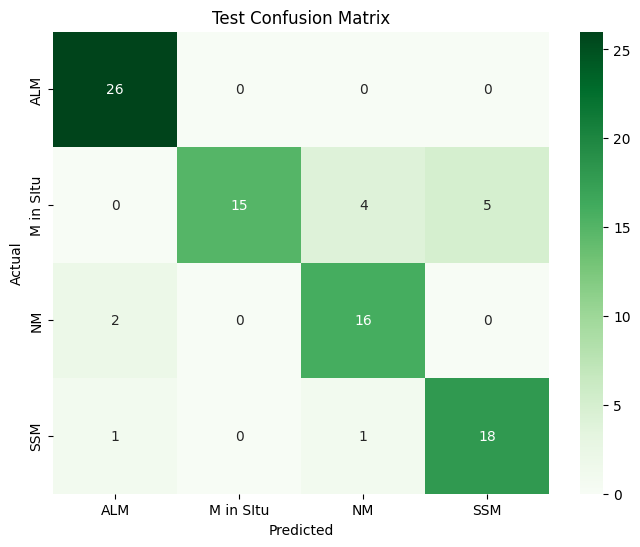

XGBoost model saved to xgboost_MobileNetV2_RGB_model.joblib
Model loaded from /kaggle/working/xgboost_MobileNetV2_RGB_model.joblib
Found 88 images belonging to 4 classes.


/tmp/ipykernel_30/2157012318.py:132: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, pooling='avg')
/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step 
Predictions, True Labels, and Confidence Scores:
                                    Image  True Label  Prediction  Confidence
0               ALM/d132642d-IMG_2864.JPG           0           0    0.999905
1               ALM/d1805016-IMG_1912.JPG           0           0    0.999090
2               ALM/d27694e9-IMG_2746.JPG           0           0    0.992763
3               ALM/d55466c0-IMG_2954.JPG           0           0    0.999548
4               ALM/d7060567-IMG_1911.JPG           0           0    0.999705
..                                    ...         ...         ...         ...
83  SSM/e2e461f8-ISIC_0023290_flipped.JPG           3           3    0.996136
84              SSM/e55f3358-IMG_2128.JPG           3           0    0.464449
85      SSM/e55f3358-IMG_2128_flipped.JPG           3           2    0.555489
86          SSM/e9a09f6b-ISIC_0023277.JPG           3           3    0.996700
87  SSM/e9a09f6b-ISIC_0023277_flipped.JPG           3  

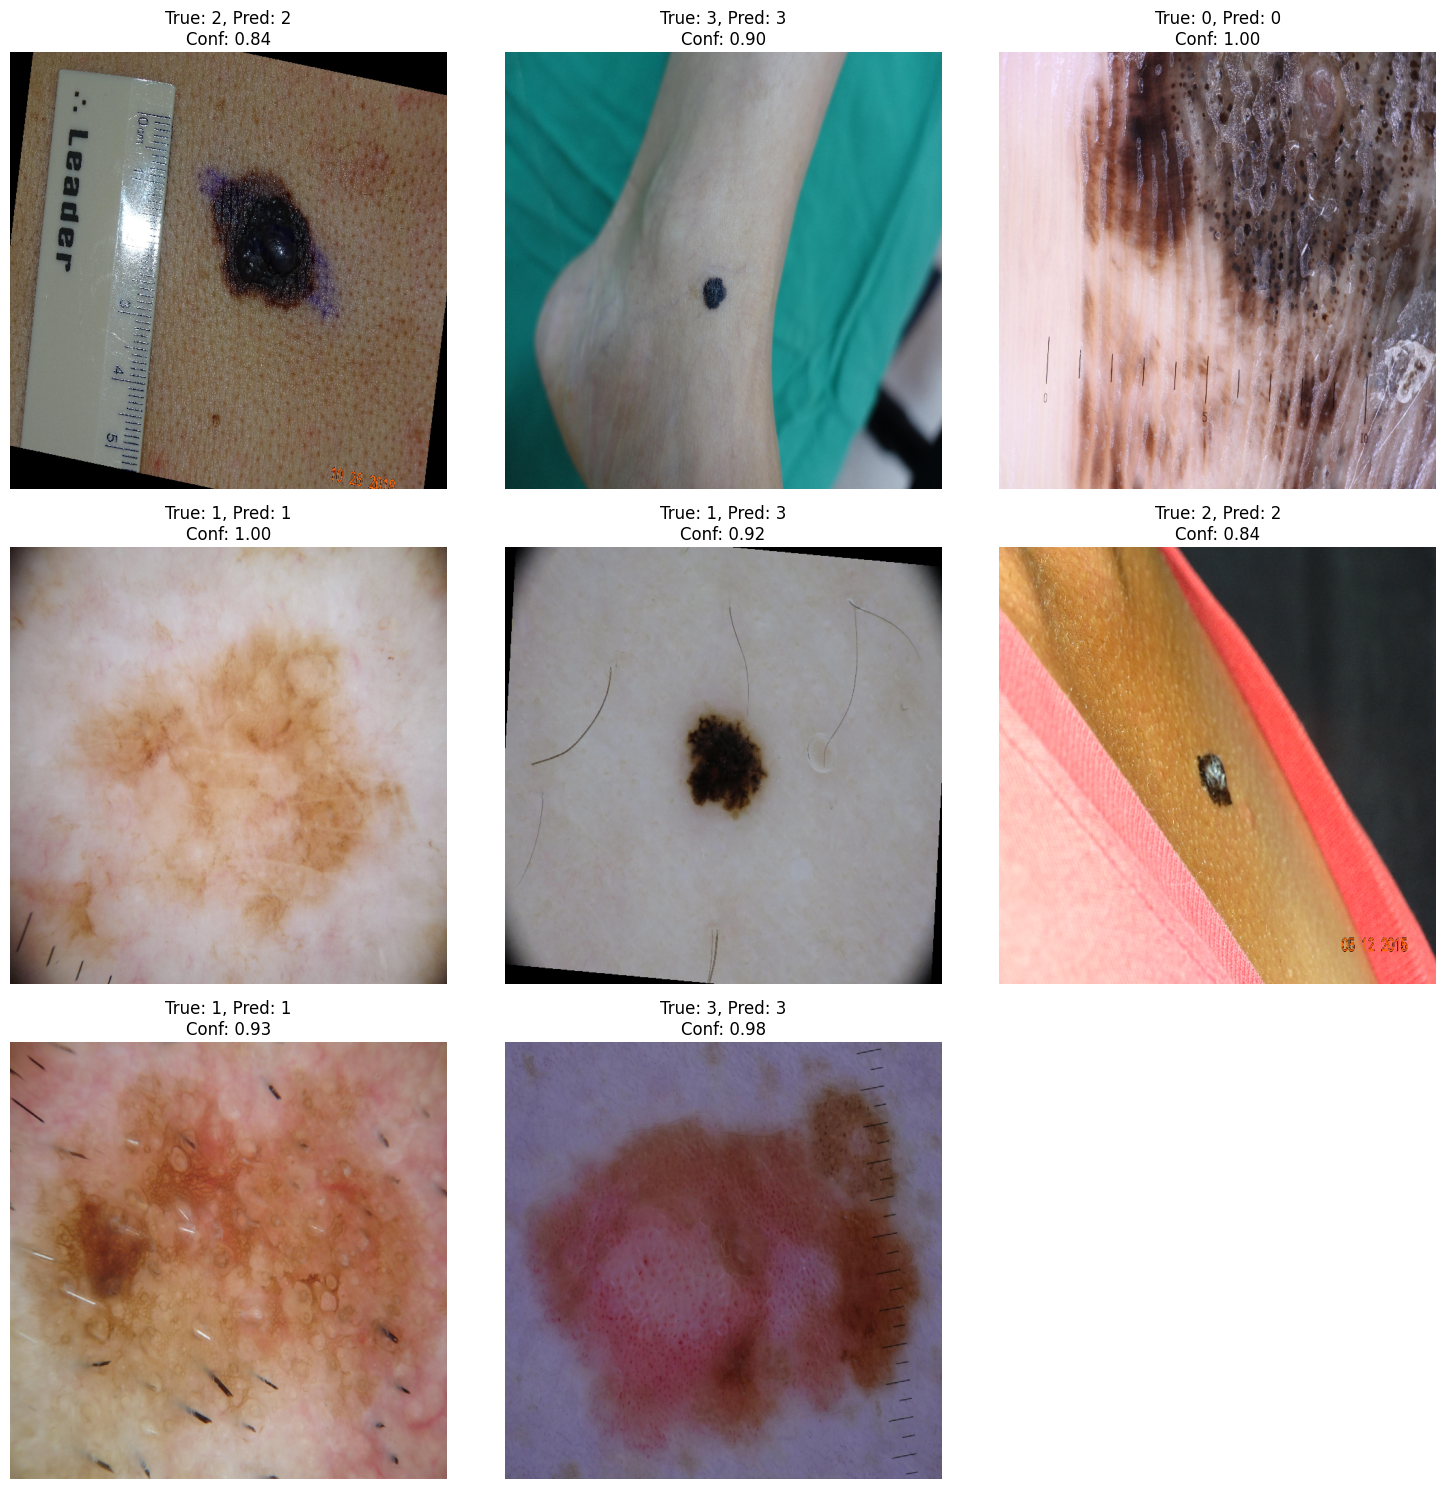

Predictions saved to test_predictions_xgb_mobilenetv2.csv


In [4]:
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pandas as pd


train_dir = '/kaggle/input/train-rgb'
val_dir = '/kaggle/input/valid-rgb'
test_dir = '/kaggle/input/test-rgb'


model_path = 'xgboost_MobileNetV2_RGB_model.joblib'


base_model = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, pooling='avg')

datagen = ImageDataGenerator(rescale=1./255)


train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary',  
    shuffle=False
)

val_generator = datagen.flow_from_directory(
    val_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

def extract_features(generator):
    features = base_model.predict(generator)
    labels = generator.classes
    return features, labels


train_features, train_labels = extract_features(train_generator)
val_features, val_labels = extract_features(val_generator)
test_features, test_labels = extract_features(test_generator)


xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
xgb_model.fit(train_features, train_labels)


val_predictions = xgb_model.predict(val_features)
print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions))

val_cm = confusion_matrix(val_labels, val_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(val_cm, annot=True, fmt="d", cmap="Blues", xticklabels=train_generator.class_indices.keys(), yticklabels=train_generator.class_indices.keys())
plt.title("Validation Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


test_predictions = xgb_model.predict(test_features)
print("Test Classification Report:")
print(classification_report(test_labels, test_predictions))

# Confusion Matrix for test set
test_cm = confusion_matrix(test_labels, test_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Greens", xticklabels=test_generator.class_indices.keys(), yticklabels=test_generator.class_indices.keys())
plt.title("Test Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

# Save the model weights
joblib.dump(xgb_model, model_path)
print(f"XGBoost model saved to {model_path}")

# Save predictions with confidence scores
pred_proba = xgb_model.predict_proba(test_features)
predictions_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'Prediction': test_predictions,
    'Confidence': [max(proba) for proba in pred_proba]
})

import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import xgboost as xgb
import joblib
import pandas as pd
import matplotlib.pyplot as plt

# Paths to test directory and saved model
test_dir = '/kaggle/input/test-rgb'
model_path = '/kaggle/working/xgboost_MobileNetV2_RGB_model.joblib'

# Load the saved model
xgb_model = joblib.load(model_path)
print(f"Model loaded from {model_path}")

# ImageDataGenerator for test data (adjust if needed)
datagen = ImageDataGenerator(rescale=1./255)
test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

# Extract test features using MobileNetV2
base_model = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, pooling='avg')

def extract_features(generator):
    features = base_model.predict(generator)
    return features

# Extract features from the test set
test_features = extract_features(test_generator)

# Predict using the loaded XGBoost model
test_predictions = xgb_model.predict(test_features)
pred_proba = xgb_model.predict_proba(test_features)

# Prepare a DataFrame with true labels, predictions, and confidence scores
predictions_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'True Label': test_generator.classes,  # True labels from the test_generator
    'Prediction': test_predictions,
    'Confidence': [max(proba) for proba in pred_proba]
})

# Print the predictions, true labels, and their confidence values
print("Predictions, True Labels, and Confidence Scores:")
print(predictions_df[['Image', 'True Label', 'Prediction', 'Confidence']])

# Display random images with their true labels, predictions, and confidence
num_images = 8
indices = np.random.choice(len(predictions_df), num_images, replace=False)

plt.figure(figsize=(15, 15))
for i, idx in enumerate(indices):
    img_path = os.path.join(test_dir, predictions_df.loc[idx, 'Image'])
    img = image.load_img(img_path, target_size=(640, 640))
    img_array = image.img_to_array(img) / 255.0  # Scale the image for display
    
    true_label = predictions_df.loc[idx, 'True Label']
    predicted_label = predictions_df.loc[idx, 'Prediction']
    confidence = predictions_df.loc[idx, 'Confidence']

    plt.subplot(3, 3, i + 1)
    plt.imshow(img_array)
    plt.axis('off')
    plt.title(f"True: {true_label}, Pred: {predicted_label}\nConf: {confidence:.2f}")

plt.tight_layout()
plt.show()

# Save predictions to CSV
predictions_df.to_csv("test_predictions_xgb_RGBmobilenetv2.csv", index=False)
print("Predictions saved to test_predictions_xgb_mobilenetv2.csv")

